# PyTorch 입문 — 다출력 선형 · 학습 루프

NumPy 표(5×4 입력 · 5×2 정답)를 텐서로 바꾸고, `nn.Linear(4, 2)` · `MSELoss` · `SGD`로 짧게 학습합니다.  
이론 복습: [`../session08.md`](../session08.md)

> **이 노트북이 하는 일**  
> 표 → 텐서 → `Linear(4, 2)` → MSE · SGD(`lr=1e-4`) → **배치** epoch 루프.  
> 이어서 **비교용**으로 `zip` 샘플별 학습 · 전체 손실 · Answer/Predict 그래프를 봅니다.

환경: `torch-env` 커널을 쓰는 것을 권장합니다.

## 1. import · seed

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from torch import optim

torch.manual_seed(1)

## 2. NumPy 표 → 텐서

입력은 5행 4열, 정답은 5행 2열입니다.

In [3]:
input_ = np.array(
    [
        [63, 56, 34, 2],
        [96, 78, 39, 1],
        [52, 106, 33, 2],
        [77, 56, 36, 5],
        [114, 98, 35, 7],
    ],
    dtype="float32",
)
input_.dtype

dtype('float32')

In [4]:
label_ = np.array(
    [
        [56, 80],
        [91, 80],
        [120, 144],
        [34, 65],
        [100, 155],
    ],
    dtype="float32",
)
label_.dtype

dtype('float32')

In [5]:
input_ = torch.from_numpy(input_)
label_ = torch.from_numpy(label_)
print(input_.shape, label_.shape)

torch.Size([5, 4]) torch.Size([5, 2])


## 3. 모델 · 손실 · Optimizer

`Linear(4, 2)`는 weight 8개 · bias 2개입니다. 학습률은 `1e-4`입니다.

In [6]:
model = nn.Linear(in_features=4, out_features=2)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=1e-4)
# 1e-4: 0.0001 - 학습률.
# 너무 크면 흔들리고 너무 작으면 학습이 느림
# 예제로 쓰기 좋은 임의에 가까운 작은 값

print("학습 전 state_dict:")
print(model.state_dict())

학습 전 state_dict:
OrderedDict([('weight', tensor([[ 0.2576, -0.2207, -0.0969,  0.2347],
        [-0.4707,  0.2999, -0.1029,  0.2544]])), ('bias', tensor([ 0.0695, -0.0612]))])


## 4. 학습 루프 — 배치(표 전체)

매 epoch마다 표 전체를 한 번에 넣고 `zero_grad` → `backward` → `step` 순서를 지킵니다.

In [7]:
for epoch in range(100):
    y_pred = model(input_)
    loss = criterion(y_pred, label_)

    optimizer.zero_grad()  # 이전 기울기 비우기
    loss.backward()
    optimizer.step()  # weight · bias 갱신

    if epoch % 20 == 0 or epoch == 99:
        print(f"epoch {epoch:3d} | loss={loss.item():.4f}")

epoch   0 | loss=11805.4326
epoch  20 | loss=274.8787
epoch  40 | loss=192.1015
epoch  60 | loss=169.5995
epoch  80 | loss=159.8573
epoch  99 | loss=153.6546


## 5. 학습 후 state_dict

In [8]:
print("학습 후 state_dict:")
print(model.state_dict())

학습 후 state_dict:
OrderedDict([('weight', tensor([[-0.1722,  1.2815, -0.1817,  0.0547],
        [-0.0190,  1.4903, -0.3395,  0.4673]])), ('bias', tensor([ 0.0671, -0.0615]))])


## 6. 비교용 — `zip` 샘플별 학습

배치와 숫자를 섞지 않으려면 **모델을 다시 만들고** 돌립니다.  
`zip`은 입력 한 줄과 정답 한 줄을 한 쌍으로 묶어 줍니다.

In [9]:
torch.manual_seed(1)
model_sample = nn.Linear(in_features=4, out_features=2)
criterion_sample = nn.MSELoss()
optimizer_sample = optim.SGD(model_sample.parameters(), lr=1e-4)

for epoch in range(100):
    for x, y in zip(input_, label_):
        yhat = model_sample(x)
        loss1 = criterion_sample(yhat, y)

        optimizer_sample.zero_grad()  # 이전 기울기 비우기
        loss1.backward()
        optimizer_sample.step()  # weight · bias 갱신

    if epoch % 20 == 0 or epoch == 99:
        print(f"epoch {epoch:3d} | last_sample_loss={loss1.item():.4f}")

epoch   0 | last_sample_loss=2583.3491
epoch  20 | last_sample_loss=236.3143
epoch  40 | last_sample_loss=113.3592
epoch  60 | last_sample_loss=84.0196
epoch  80 | last_sample_loss=75.0269
epoch  99 | last_sample_loss=71.7702


## 7. 전체 손실 · Answer vs Predict

표 전체를 한 번에 넣어 **전체 MSE**를 보고, 첫 출력 열만 Answer/Predict로 그립니다.

In [ ]:
pred = model_sample(input_)
full_loss = criterion_sample(pred, label_)
print("전체 MSE:", full_loss.item())
# detach().numpy()는 텐서를 넘파이 배열로 변환하는 함수
print("정답:\n", label_.detach().numpy())
print("예측:\n", pred.detach().numpy())

전체 MSE: 566.1483154296875
정답:
 [[ 56.  80.]
 [ 91.  80.]
 [120. 144.]
 [ 34.  65.]
 [100. 155.]]
예측:
 [[ 37.057903  82.5154  ]
 [ 67.05585  116.12398 ]
 [101.51078  193.20653 ]
 [ 37.21413   84.1908  ]
 [103.52025  171.24638 ]]


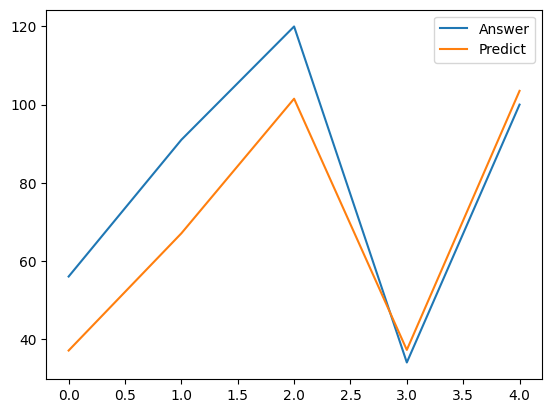

In [11]:
plt.plot(label_[:, 0].detach().numpy(), label="Answer")
plt.plot(pred[:, 0].detach().numpy(), label="Predict")
plt.legend()
plt.show()

---

이론 복습: [`../session08.md`](../session08.md) · 커스텀 Module: [`08_custom_linear_module.ipynb`](./08_custom_linear_module.ipynb)  
다음: [`../session09.md`](../session09.md) · [`10_boston_mlp.ipynb`](./10_boston_mlp.ipynb)